# 07 — Feature comparison

## Purpose

We examine how Gregorian, solar, lunar, and Vedic Panchang features change the forecasting accuracy of the LightGBM model developed in Notebook 06.

Our main comparison is **F3 versus F4**. F3 includes continuous solar and lunar information, while F4 adds the five Panchang categories. We also compare these representations after adding four continuous sidereal-angle features.

We analyze predictions from three chronological development folds at forecast horizons of **15, 30, and 60 minutes**. The paired comparisons use the same observations for both feature sets.

## 1. Load the development predictions

Notebook 06 recorded each forecast, its observed PV power, and the predictions from seven feature representations and two persistence baselines. We use those predictions to calculate comparable forecasting errors.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

PROJECT_ROOT = next(
    (
        folder for folder in (Path.cwd(), *Path.cwd().parents)
        if (folder / "results" / "feature_comparison" /
            "solete_development_predictions.csv.gz").is_file()
    ),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Run Notebook 06 first so the development predictions are available."
    )
PROJECT_ROOT = PROJECT_ROOT.resolve()
RESULTS_DIR = PROJECT_ROOT / "results" / "feature_comparison"

predictions = pd.read_csv(
    RESULTS_DIR / "solete_development_predictions.csv.gz",
    parse_dates=["issue_time_UTC", "valid_time_UTC"],
)
fold_metrics = pd.read_csv(
    RESULTS_DIR / "solete_development_fold_metrics.csv"
)
recorded_contrasts = pd.read_csv(
    RESULTS_DIR / "solete_development_feature_contrasts.csv"
)

HORIZONS = (15, 30, 60)
FAMILIES = (
    "F0", "F1", "F2", "F3", "F4", "F3_sidereal", "F4_sidereal"
)
METHODS = FAMILIES + ("issue_persistence", "previous_day_persistence")
COMPARISONS = (
    ("Gregorian", "F0", "F1"),
    ("Solar", "F1", "F2"),
    ("Continuous lunar", "F2", "F3"),
    ("Panchang", "F3", "F4"),
    ("Panchang with sidereal control", "F3_sidereal", "F4_sidereal"),
)

required = {
    "horizon_min", "fold", "issue_time_UTC", "valid_time_UTC",
    "actual_kw", "daylight", *METHODS,
}
assert required.issubset(predictions.columns)
assert len(predictions) == 157_212
assert set(predictions["horizon_min"]) == set(HORIZONS)
assert set(predictions["fold"]) == {1, 2, 3}
assert predictions["issue_time_UTC"].dt.tz is not None
assert predictions["valid_time_UTC"].dt.tz is not None
assert predictions["daylight"].isin([0, 1]).all()
assert predictions.duplicated(["horizon_min", "issue_time_UTC"]).sum() == 0
assert np.isfinite(predictions[["actual_kw", *METHODS]].to_numpy()).all()
assert (
    predictions["valid_time_UTC"] - predictions["issue_time_UTC"]
    == pd.to_timedelta(predictions["horizon_min"], unit="min")
).all()
assert len(fold_metrics) == 162 and len(recorded_contrasts) == 30

sample_counts = predictions.groupby(["horizon_min", "fold"]).size().unstack()
assert (sample_counts.to_numpy() == np.array([17856, 16992, 17556])).all()
print("Validation samples by horizon and fold:")
display(sample_counts)

Validation samples by horizon and fold:


fold,1,2,3
horizon_min,,,
15,17856,16992,17556
30,17856,16992,17556
60,17856,16992,17556


## 2. Verify the forecast errors

We calculate mean absolute error (MAE) and root mean square error (RMSE) from the saved predictions. We calculate scores for the complete validation period and for observations when the Sun is above the horizon.

We compare the recalculated values with the scores saved by Notebook 06.

In [2]:
score_rows = []
for (horizon, fold), group in predictions.groupby(["horizon_min", "fold"], sort=True):
    for scope, selected in (
        ("all", group),
        ("daylight", group.loc[group["daylight"].eq(1)]),
    ):
        assert len(selected) > 0
        actual = selected["actual_kw"].to_numpy()
        for method in METHODS:
            residual = actual - selected[method].to_numpy()
            score_rows.append({
                "horizon_min": horizon,
                "fold": fold,
                "scope": scope,
                "method": method,
                "n": len(selected),
                "mae_kw": np.abs(residual).mean(),
                "rmse_kw": np.sqrt(np.square(residual).mean()),
            })

calculated_metrics = pd.DataFrame(score_rows)
keys = ["horizon_min", "fold", "scope", "method"]
check = calculated_metrics.merge(
    fold_metrics, on=keys, how="outer", validate="one_to_one",
    suffixes=("_calculated", "_recorded"), indicator=True,
)
assert len(check) == 162 and check["_merge"].eq("both").all()
for field in ("n", "mae_kw", "rmse_kw"):
    np.testing.assert_allclose(
        check[f"{field}_calculated"], check[f"{field}_recorded"],
        rtol=0, atol=1e-8,
    )

fold_means = (
    calculated_metrics.groupby(["horizon_min", "scope", "method"], as_index=False)
    .agg(mean_mae_kw=("mae_kw", "mean"))
)
all_hours = fold_means.loc[fold_means["scope"].eq("all")]
accuracy = all_hours.pivot(index="horizon_min", columns="method", values="mean_mae_kw")
print("Mean of the three validation-fold MAEs (kW):")
display(accuracy[list(METHODS)].round(5))
print("Saved and recalculated error scores agree.")

Mean of the three validation-fold MAEs (kW):


method,F0,F1,F2,F3,F4,F3_sidereal,F4_sidereal,issue_persistence,previous_day_persistence
horizon_min,,,,,,,,,
15,0.18746,0.17734,0.17825,0.18081,0.17919,0.18071,0.18072,0.18336,0.51892
30,0.24309,0.22188,0.21911,0.22278,0.22190,0.22541,0.22467,0.24968,0.51892
60,0.32847,0.28648,0.28101,0.28686,0.28545,0.28936,0.28982,0.36331,0.51892


Saved and recalculated error scores agree.


## 3. Compare the feature additions

For each feature addition, we subtract the MAE of the larger representation from the MAE of its reference:

\[
\Delta=\operatorname{MAE}_{\mathrm{reference}}-\operatorname{MAE}_{\mathrm{augmented}}.
\]

A **positive difference** means the added features reduced the forecasting error. A **negative difference** means the reference features performed better. We calculate the difference using the average of the three fold MAEs.

In [3]:
comparison_rows = []
for (horizon, scope), group in fold_means.groupby(["horizon_min", "scope"]):
    by_method = group.set_index("method")["mean_mae_kw"]
    for name, reference, augmented in COMPARISONS:
        ref_mae, aug_mae = by_method[reference], by_method[augmented]
        comparison_rows.append({
            "horizon_min": horizon,
            "scope": scope,
            "comparison": name,
            "reference": reference,
            "augmented": augmented,
            "mae_reduction_kw": ref_mae - aug_mae,
            "relative_reduction_pct": 100 * (1 - aug_mae / ref_mae),
        })
comparisons = pd.DataFrame(comparison_rows)
comparison_keys = ["horizon_min", "scope", "comparison", "reference", "augmented"]
reconciled = comparisons.merge(
    recorded_contrasts, on=comparison_keys, how="outer",
    validate="one_to_one", suffixes=("_calculated", "_recorded"), indicator=True,
)
assert len(reconciled) == 30 and reconciled["_merge"].eq("both").all()
for field in ("mae_reduction_kw", "relative_reduction_pct"):
    np.testing.assert_allclose(
        reconciled[f"{field}_calculated"],
        reconciled[f"{field}_recorded"], atol=1e-8, rtol=0,
    )

print("All-hours feature comparisons:")
display(comparisons.loc[comparisons["scope"].eq("all")].round(5))
print("Panchang comparisons during daylight:")
display(comparisons.loc[
    comparisons["scope"].eq("daylight")
    & comparisons["comparison"].str.startswith("Panchang")
].round(5))

All-hours feature comparisons:


,horizon_min,scope,comparison,reference,augmented,mae_reduction_kw,relative_reduction_pct
0,15,all,Gregorian,F0,F1,0.01012,5.39761
1,15,all,Solar,F1,F2,-0.00091,-0.51108
2,15,all,Continuous lunar,F2,F3,-0.00256,-1.43421
3,15,all,Panchang,F3,F4,0.00162,0.89713
4,15,all,Panchang with sidereal control,F3_sidereal,F4_sidereal,-0.00001,-0.00615
10,30,all,Gregorian,F0,F1,0.02120,8.72241
11,30,all,Solar,F1,F2,0.00278,1.25117
12,30,all,Continuous lunar,F2,F3,-0.00367,-1.67452
13,30,all,Panchang,F3,F4,0.00088,0.39443
14,30,all,Panchang with sidereal control,F3_sidereal,F4_sidereal,0.00074,0.32701


Panchang comparisons during daylight:


,horizon_min,scope,comparison,reference,augmented,mae_reduction_kw,relative_reduction_pct
8,15,daylight,Panchang,F3,F4,0.00322,0.87836
9,15,daylight,Panchang with sidereal control,F3_sidereal,F4_sidereal,-0.00014,-0.03779
18,30,daylight,Panchang,F3,F4,0.00173,0.37661
19,30,daylight,Panchang with sidereal control,F3_sidereal,F4_sidereal,0.00279,0.60233
28,60,daylight,Panchang,F3,F4,0.00381,0.63853
29,60,daylight,Panchang with sidereal control,F3_sidereal,F4_sidereal,-0.00137,-0.22896


## 4. Check how results vary between folds

The fold averages summarize overall performance, but different validation periods can produce different outcomes. We therefore calculate each feature-pair difference separately in all three folds.

This helps us see whether an overall error reduction occurs repeatedly or is driven by a particular period.

In [4]:
fold_effects = []
for (horizon, fold, scope), group in calculated_metrics.groupby(
    ["horizon_min", "fold", "scope"]
):
    by_method = group.set_index("method")["mae_kw"]
    for name, reference, augmented in COMPARISONS:
        fold_effects.append({
            "horizon_min": horizon,
            "fold": fold,
            "scope": scope,
            "comparison": name,
            "reference": reference,
            "augmented": augmented,
            "mae_reduction_kw": by_method[reference] - by_method[augmented],
        })
fold_effects = pd.DataFrame(fold_effects)
fold_detail = fold_effects.loc[
    fold_effects["comparison"].str.startswith("Panchang")
    & fold_effects["scope"].eq("all")
]
print("Panchang error reductions by validation fold (kW):")
display(fold_detail.pivot_table(
    index=["horizon_min", "comparison"], columns="fold", values="mae_reduction_kw",
).round(5))

consistency = (
    fold_effects.groupby(["horizon_min", "scope", "comparison"], as_index=False)
    .agg(folds_with_lower_mae=("mae_reduction_kw", lambda x: int((x > 0).sum())),
         folds_with_higher_mae=("mae_reduction_kw", lambda x: int((x < 0).sum())))
)
assert len(fold_effects) == 90 and len(consistency) == 30

Panchang error reductions by validation fold (kW):


fold                                              1        2        3
horizon_min comparison                                               
15          Panchang                        0.00053  0.00213  0.00220
            Panchang with sidereal control -0.00078 -0.00081  0.00156
30          Panchang                       -0.00219  0.00246  0.00237
            Panchang with sidereal control  0.00092 -0.00057  0.00186
60          Panchang                       -0.00301  0.00233  0.00493
            Panchang with sidereal control -0.00415 -0.00135  0.00414

## 5. Estimate uncertainty using paired daily resampling

Forecast errors on nearby timestamps are related. To account for some of this dependence, we resample **complete UTC days** instead of individual observations.

Within each chronological validation fold, we sample days with replacement and recalculate the MAE for both representations using the **same sampled days**. We then average the three fold MAEs. We repeat this 10,000 times and report the central 95% interval for the paired MAE reduction.

These intervals describe variation in the recorded predictions across validation days. They do not include variation caused by fitting models again with different training samples or random seeds. The feature comparisons also form a related set of exploratory analyses.

In [5]:
BOOTSTRAP_REPETITIONS = 10_000
rng = np.random.default_rng(42)
bootstrap_rows = []

# Each comparison within the same horizon and scope uses matched daily samples.
for horizon in HORIZONS:
    by_horizon = predictions.loc[predictions["horizon_min"].eq(horizon)].copy()
    by_horizon["utc_day"] = by_horizon["valid_time_UTC"].dt.floor("D")
    for scope in ("all", "daylight"):
        selected = (
            by_horizon if scope == "all"
            else by_horizon.loc[by_horizon["daylight"].eq(1)]
        )
        sampled_mae_by_fold = []
        for fold in (1, 2, 3):
            part = selected.loc[selected["fold"].eq(fold)].copy()
            assert len(part) > 0
            for method in METHODS:
                part[f"err_{method}"] = (
                    part["actual_kw"] - part[method]
                ).abs()
            error_columns = [f"err_{method}" for method in METHODS]
            daily_errors = part.groupby("utc_day")[error_columns].sum()
            daily_counts = part.groupby("utc_day").size().reindex(daily_errors.index)
            assert len(daily_errors) >= 20
            days = len(daily_errors)
            day_selection = rng.integers(0, days, size=(BOOTSTRAP_REPETITIONS, days))
            sample_counts = daily_counts.to_numpy()[day_selection].sum(axis=1)
            fold_mae = {}
            for method in METHODS:
                totals = daily_errors[f"err_{method}"].to_numpy()
                fold_mae[method] = totals[day_selection].sum(axis=1) / sample_counts
            sampled_mae_by_fold.append(fold_mae)

        for name, reference, augmented in COMPARISONS:
            per_fold_draws = [
                fold_sample[reference] - fold_sample[augmented]
                for fold_sample in sampled_mae_by_fold
            ]
            draws = np.mean(np.stack(per_fold_draws), axis=0)
            bounds = np.quantile(draws, [0.025, 0.975])
            observed = comparisons.loc[
                comparisons["horizon_min"].eq(horizon)
                & comparisons["scope"].eq(scope)
                & comparisons["comparison"].eq(name),
                "mae_reduction_kw",
            ].item()
            bootstrap_rows.append({
                "horizon_min": horizon,
                "scope": scope,
                "comparison": name,
                "reference": reference,
                "augmented": augmented,
                "mae_reduction_kw": observed,
                "ci_lower_kw": bounds[0],
                "ci_upper_kw": bounds[1],
                "direction": (
                    "Added features lower MAE" if bounds[0] > 0 else
                    "Reference features lower MAE" if bounds[1] < 0 else
                    "Unresolved"
                ),
            })

bootstrap_results = pd.DataFrame(bootstrap_rows)
assert len(bootstrap_results) == 30
assert (bootstrap_results["ci_lower_kw"] <= bootstrap_results["ci_upper_kw"]).all()
assert np.isfinite(bootstrap_results[[
    "mae_reduction_kw", "ci_lower_kw", "ci_upper_kw"
]].to_numpy()).all()

print("Panchang comparisons with paired daily intervals (kW):")
display(bootstrap_results.loc[
    bootstrap_results["comparison"].str.startswith("Panchang")
].round(5))

Panchang comparisons with paired daily intervals (kW):


,horizon_min,scope,comparison,reference,augmented,mae_reduction_kw,ci_lower_kw,ci_upper_kw,direction
3,15,all,Panchang,F3,F4,0.00162,0.00080,0.00245,Added features lower MAE
4,15,all,Panchang with sidereal control,F3_sidereal,F4_sidereal,-0.00001,-0.00121,0.00111,Unresolved
8,15,daylight,Panchang,F3,F4,0.00322,0.00164,0.00485,Added features lower MAE
9,15,daylight,Panchang with sidereal control,F3_sidereal,F4_sidereal,-0.00014,-0.00258,0.00224,Unresolved
13,30,all,Panchang,F3,F4,0.00088,-0.00057,0.00232,Unresolved
14,30,all,Panchang with sidereal control,F3_sidereal,F4_sidereal,0.00074,-0.00082,0.00234,Unresolved
18,30,daylight,Panchang,F3,F4,0.00173,-0.00135,0.00475,Unresolved
19,30,daylight,Panchang with sidereal control,F3_sidereal,F4_sidereal,0.00279,-0.00059,0.00611,Unresolved
23,60,all,Panchang,F3,F4,0.00142,-0.00089,0.00364,Unresolved
24,60,all,Panchang with sidereal control,F3_sidereal,F4_sidereal,-0.00045,-0.00339,0.00247,Unresolved


## 6. Visualize the Panchang comparisons

The figure shows how much MAE changes when the five Panchang feature families are added to F3. The vertical ranges are the paired daily-resampling intervals. Results above zero favor F4; results below zero favor F3.

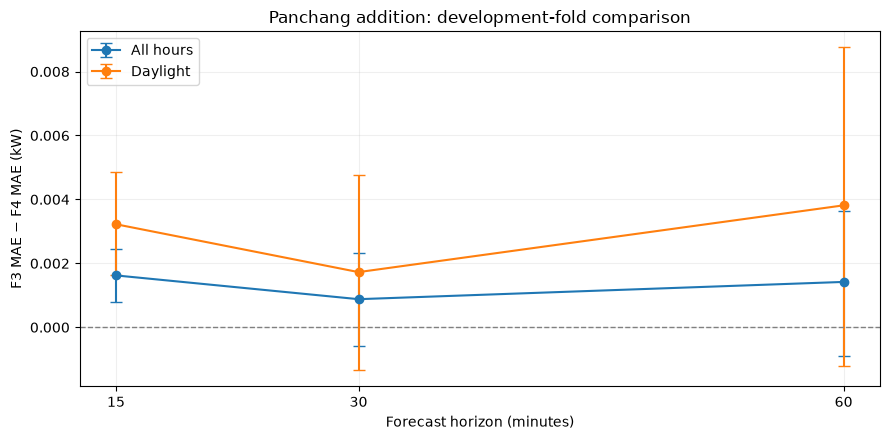

In [6]:
primary = bootstrap_results.loc[
    bootstrap_results["comparison"].eq("Panchang")
].copy()
fig, ax = plt.subplots(figsize=(9, 4.5))
for scope, label in (("all", "All hours"), ("daylight", "Daylight")):
    series = primary.loc[primary["scope"].eq(scope)].sort_values("horizon_min")
    x = series["horizon_min"].to_numpy()
    y = series["mae_reduction_kw"].to_numpy()
    lower = series["ci_lower_kw"].to_numpy()
    upper = series["ci_upper_kw"].to_numpy()
    ax.errorbar(x, y, yerr=np.vstack([y - lower, upper - y]),
                fmt="o-", capsize=4, label=label)
ax.axhline(0, color="gray", linestyle="--", linewidth=1)
ax.set_xticks(HORIZONS)
ax.set_xlabel("Forecast horizon (minutes)")
ax.set_ylabel("F3 MAE − F4 MAE (kW)")
ax.set_title("Panchang addition: development-fold comparison")
ax.grid(alpha=0.2)
ax.legend()
plt.tight_layout()
plt.show()

## 7. Summarize the forecasting evidence

We compare the size and direction of the Panchang effect with its uncertainty range and fold consistency. The same summary includes the additional continuous-sidereal control.

In [7]:
panchang_evidence = bootstrap_results.loc[
    bootstrap_results["comparison"].str.startswith("Panchang")
].merge(
    consistency,
    on=["horizon_min", "scope", "comparison"],
    validate="one_to_one",
)
print("Panchang evidence and fold consistency:")
display(panchang_evidence[[
    "horizon_min", "scope", "comparison", "mae_reduction_kw",
    "ci_lower_kw", "ci_upper_kw", "direction",
    "folds_with_lower_mae", "folds_with_higher_mae",
]].round(5))

print("Primary all-hours interpretation:")
for row in primary.loc[primary["scope"].eq("all")].sort_values("horizon_min").itertuples():
    direction = (
        "lower" if row.mae_reduction_kw > 0 else
        "higher" if row.mae_reduction_kw < 0 else "equal"
    )
    print(
        f"{row.horizon_min} min: F4 has {direction} mean MAE than F3 "
        f"by {abs(row.mae_reduction_kw):.5f} kW; "
        f"95% interval for F3 − F4: "
        f"[{row.ci_lower_kw:.5f}, {row.ci_upper_kw:.5f}] kW "
        f"({row.direction.lower()})."
    )

Panchang evidence and fold consistency:


,horizon_min,scope,comparison,mae_reduction_kw,ci_lower_kw,ci_upper_kw,direction,folds_with_lower_mae,folds_with_higher_mae
0,15,all,Panchang,0.00162,0.00080,0.00245,Added features lower MAE,3,0
1,15,all,Panchang with sidereal control,-0.00001,-0.00121,0.00111,Unresolved,1,2
2,15,daylight,Panchang,0.00322,0.00164,0.00485,Added features lower MAE,3,0
3,15,daylight,Panchang with sidereal control,-0.00014,-0.00258,0.00224,Unresolved,1,2
4,30,all,Panchang,0.00088,-0.00057,0.00232,Unresolved,2,1
5,30,all,Panchang with sidereal control,0.00074,-0.00082,0.00234,Unresolved,2,1
6,30,daylight,Panchang,0.00173,-0.00135,0.00475,Unresolved,2,1
7,30,daylight,Panchang with sidereal control,0.00279,-0.00059,0.00611,Unresolved,2,1
8,60,all,Panchang,0.00142,-0.00089,0.00364,Unresolved,2,1
9,60,all,Panchang with sidereal control,-0.00045,-0.00339,0.00247,Unresolved,1,2


Primary all-hours interpretation:
15 min: F4 has lower mean MAE than F3 by 0.00162 kW; 95% interval for F3 − F4: [0.00080, 0.00245] kW (added features lower mae).
30 min: F4 has lower mean MAE than F3 by 0.00088 kW; 95% interval for F3 − F4: [-0.00057, 0.00232] kW (unresolved).
60 min: F4 has lower mean MAE than F3 by 0.00142 kW; 95% interval for F3 − F4: [-0.00089, 0.00364] kW (unresolved).


## 8. Save the comparison results

The paired comparisons, fold consistency table and daily-resampling intervals provide the quantitative evidence for our Panchang analysis.

In [8]:
comparison_path = RESULTS_DIR / "solete_feature_comparison_intervals.csv"
fold_path = RESULTS_DIR / "solete_feature_fold_consistency.csv"
bootstrap_results.to_csv(comparison_path, index=False, float_format="%.12g")
fold_effects.to_csv(fold_path, index=False, float_format="%.12g")

saved_comparisons = pd.read_csv(comparison_path)
saved_fold_effects = pd.read_csv(fold_path)
assert len(saved_comparisons) == 30
assert len(saved_fold_effects) == 90
assert saved_comparisons["ci_lower_kw"].notna().all()
assert saved_fold_effects["mae_reduction_kw"].notna().all()
print("Saved paired comparison results:")
print(comparison_path.relative_to(PROJECT_ROOT))
print(fold_path.relative_to(PROJECT_ROOT))
print("NOTEBOOK 07: FEATURE COMPARISON CHECKS PASSED")

Saved paired comparison results:
results/feature_comparison/solete_feature_comparison_intervals.csv
results/feature_comparison/solete_feature_fold_consistency.csv
NOTEBOOK 07: FEATURE COMPARISON CHECKS PASSED


## Interpretation

The feature comparisons measure the effect of adding deterministic time and astronomy representations to the same historical forecasting information under a common LightGBM configuration.

The **F3–F4** comparison is the primary test of the incremental Panchang representation. The comparison with continuous sidereal angles provides a stronger astronomical reference. The fold-level results and paired daily-resampling intervals help distinguish repeatable error reductions from small changes that vary with the validation period.

These findings describe the SOLETE chronological development folds and the fixed LightGBM model. The resampling intervals condition on the fitted forecasts, and the multiple feature comparisons are interpreted as exploratory evidence. The Panchang alignment and coding analyses will provide further tests of how these categorical representations behave.